### Dataset
UCI Appliances Energy Prediction:
https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
from scipy import stats

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

df = pd.read_csv("smart_energy/data/energydata_complete.csv")
df["date"] = pd.to_datetime(df["date"])

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
display(df.head())
display(df.tail())
print("Shape:", df.shape)
print("Columns:", df.columns)
df.info()
display(df.describe())
print("Missing values:")
print(df.isnull().sum())

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
19730,2016-05-27 17:20:00,100,0,25.566667,46.560000,25.890000,42.025714,27.200000,41.163333,24.7,...,23.2,46.7900,22.733333,755.2,55.666667,3.333333,23.666667,13.333333,43.096812,43.096812
19731,2016-05-27 17:30:00,90,0,25.500000,46.500000,25.754000,42.080000,27.133333,41.223333,24.7,...,23.2,46.7900,22.600000,755.2,56.000000,3.500000,24.500000,13.300000,49.282940,49.282940
19732,2016-05-27 17:40:00,270,10,25.500000,46.596667,25.628571,42.768571,27.050000,41.690000,24.7,...,23.2,46.7900,22.466667,755.2,56.333333,3.666667,25.333333,13.266667,29.199117,29.199117
19733,2016-05-27 17:50:00,420,10,25.500000,46.990000,25.414000,43.036000,26.890000,41.290000,24.7,...,23.2,46.8175,22.333333,755.2,56.666667,3.833333,26.166667,13.233333,6.322784,6.322784
19734,2016-05-27 18:00:00,430,10,25.500000,46.600000,25.264286,42.971429,26.823333,41.156667,24.7,...,23.2,46.8450,22.200000,755.2,57.000000,4.000000,27.000000,13.200000,34.118851,34.118851


Shape: (19735, 29)
Columns: Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'rv1', 'rv2'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[ns]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
count,19735,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,2016-03-20 05:30:00,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,...,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,24.988033,24.988033
min,2016-01-11 17:00:00,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322
25%,2016-02-14 23:15:00,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,...,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889
50%,2016-03-20 05:30:00,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,...,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,24.897653,24.897653
75%,2016-04-23 11:45:00,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,...,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,37.583769,37.583769
max,2016-05-27 18:00:00,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530
std,NaN,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,...,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,14.496634,14.496634


Missing values:
date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64


# Practical 1 — Web Scraping

**Aim:** Official MSEDCL tariff webpage se tariff-related document links extract karna.

**Simple explanation:** `requests` webpage download karta hai. `BeautifulSoup` HTML read karta hai. Hum page par tariff/PDF related links find karte hain.

**Note:** Webpage se links milna aur actual tariff rates extract hona alag cheezein hain. Final slab rates official tariff order se verify karna.

In [4]:
url = "https://www.mahadiscom.in/en/consumer/tariff-details/"
response = requests.get(url, timeout=30)
print("Status code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")
print("Page title:", soup.title.text if soup.title else "Not found")
for link in soup.find_all("a"):
    link_name = link.get_text(strip=True)
    link_url = link.get("href")
    if link_url and ("tariff" in link_name.lower() or ".pdf" in link_url.lower()):
        print(link_name, ":", link_url)

Status code: 200


Page title: Tariff Details - Maharashtra State Electricity Distribution Co. Ltd.
Documents Required For Name changeLanguage: English : /consumer/wp-content/uploads/2018/06/DocumentsRequiredForNameChange.pdf
Activity Declaration for Change of Tariff : https://wss.mahadiscom.in/wss/wss?uiActionName=getCustAccountLogin
Activity Declaration For Change Of TariffNew : https://css.mahadiscom.in/UI/TariffChange/TariffChange.aspx
Help ManualLanguage: English : /consumer/wp-content/uploads/2024/05/Composite-Billing-MSEDCL-BR-User-Manual_new-1.pdf
Citizen CharterLanguage: English : /consumer/wp-content/uploads/2019/09/Citizen.pdf
Citizen Charter For NCE-CPPLanguage: English : /consumer/wp-content/uploads/2019/02/CitizenCharterNCE-CPP-Decision.pdf
Electricity Consumer RightsLanguage: English : /consumer/wp-content/uploads/2017/11/Consumer_Right_Statement_Eng.pdf
Supply Code, SoP including Power Quality Regulations, 2021.Language: Marathi : /wp-content/uploads/2021/07/Gazette_Notification-.pdf
Tari

# Practical 2 — Exploratory Data Analysis (EDA)

**Aim:** Dataset ko understand karna aur mean, median, mode, variance, standard deviation, minimum, maximum calculate karna.

**Simple explanation:**
- Mean = average.
- Median = middle value.
- Mode = most frequent value.
- Variance = values kitni spread hain.
- Standard deviation = average spread ka measure.
- Histogram = values ka distribution.
- Box plot = spread aur possible outliers.

In [5]:
print("Rows and columns:", df.shape)
print("Column names:", list(df.columns))
print("Missing values:", df.isnull().sum().sum())
print("Mean:", df["Appliances"].mean())
print("Median:", df["Appliances"].median())
print("Mode:", df["Appliances"].mode()[0])
print("Variance:", df["Appliances"].var())
print("Standard deviation:", df["Appliances"].std())
print("Minimum:", df["Appliances"].min())
print("Maximum:", df["Appliances"].max())
display(df[["Appliances", "lights"]].describe())

Rows and columns: (19735, 29)
Column names: ['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']
Missing values: 0
Mean: 97.6949581960983
Median: 60.0
Mode: 50
Variance: 10511.353179707132
Standard deviation: 102.52489053740624
Minimum: 10
Maximum: 1080


,Appliances,lights
count,19735.000000,19735.000000
mean,97.694958,3.801875
std,102.524891,7.935988
min,10.000000,0.000000
25%,50.000000,0.000000
50%,60.000000,0.000000
75%,100.000000,0.000000
max,1080.000000,70.000000


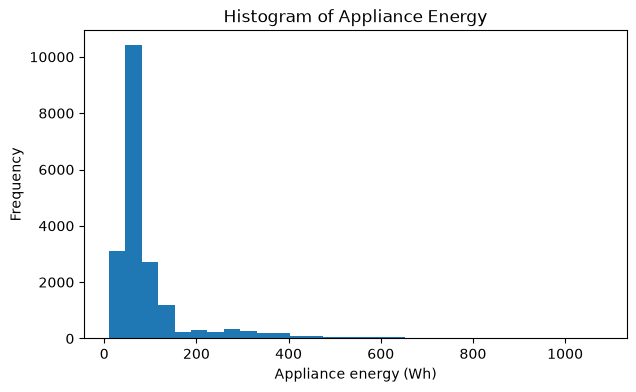

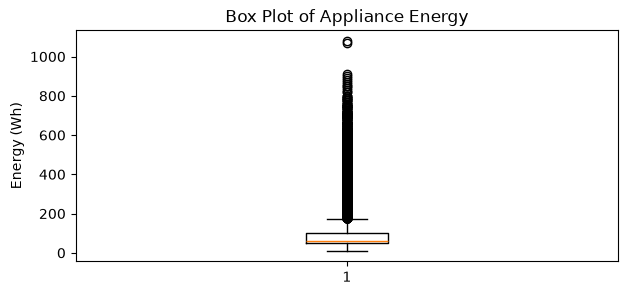

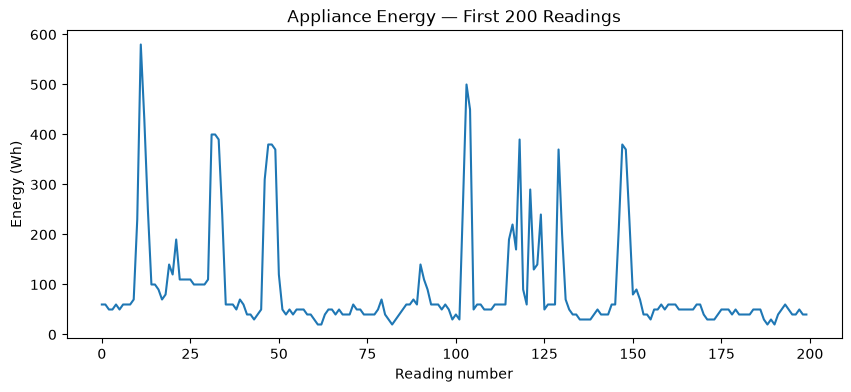

In [6]:
plt.figure(figsize=(7,4))
plt.hist(df["Appliances"], bins=30)
plt.title("Histogram of Appliance Energy")
plt.xlabel("Appliance energy (Wh)")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(7,3))
plt.boxplot(df["Appliances"])
plt.title("Box Plot of Appliance Energy")
plt.ylabel("Energy (Wh)")
plt.show()

plt.figure(figsize=(10,4))
plt.plot(df["Appliances"].head(200))
plt.title("Appliance Energy — First 200 Readings")
plt.xlabel("Reading number")
plt.ylabel("Energy (Wh)")
plt.show()

# Practical 3 — Sampling and Probability

**Aim:** Simple random, systematic and month-wise sampling perform karna. Basic probability calculate karna.

**Simple explanation:**
- Random sampling: randomly rows select karna.
- Systematic sampling: fixed interval par rows select karna.
- Stratified sampling: groups (yahan month) se sample lena.
- Probability = favourable outcomes / total outcomes.

In [7]:
daily = df.set_index("date")["Appliances"].resample("D").sum().reset_index()
ddaily = daily
daily.columns = ["Date", "Daily_Energy_Wh"]

random_sample = daily.sample(n=20, random_state=42)
print("Random sample:")
display(random_sample.head())

systematic_sample = daily.iloc[::10]
print("Systematic sample:")
display(systematic_sample.head())

daily["Month"] = daily["Date"].dt.month
stratified_sample = daily.groupby("Month").sample(n=2, random_state=42)
print("Stratified sample:")
display(stratified_sample.head(10))

average_energy = daily["Daily_Energy_Wh"].mean()
high_days = daily[daily["Daily_Energy_Wh"] > average_energy]

probability = len(high_days) / len(daily)
print("High consumption days:", len(high_days))
print("Total days:", len(daily))
print("Probability of high consumption:", probability)

Random sample:


,Date,Daily_Energy_Wh
89,2016-04-09,15150
105,2016-04-25,10820
12,2016-01-23,13400
26,2016-02-06,11980
64,2016-03-15,14010


Systematic sample:


,Date,Daily_Energy_Wh
0,2016-01-11,5740
10,2016-01-21,13340
20,2016-01-31,18640
30,2016-02-10,13880
40,2016-02-20,14510


Stratified sample:


,Date,Daily_Energy_Wh,Month
0,2016-01-11,5740,1
17,2016-01-28,5400,1
34,2016-02-14,14750,2
31,2016-02-11,15300,2
50,2016-03-01,10420,3
78,2016-03-29,13170,3
82,2016-04-02,7300,4
86,2016-04-06,12610,4
123,2016-05-13,24280,5
116,2016-05-06,14510,5


High consumption days: 54
Total days: 138
Probability of high consumption: 0.391304347826087


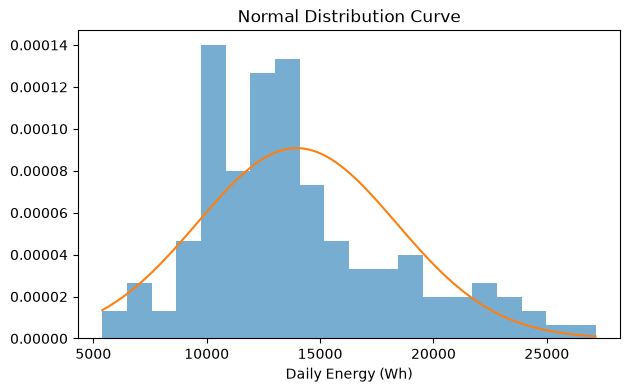

In [8]:
energy = daily["Daily_Energy_Wh"]
mean_value = energy.mean()
std_value = energy.std()

plt.figure(figsize=(7,4))
plt.hist(energy, bins=20, density=True, alpha=0.6)

x = np.linspace(energy.min(), energy.max(), 100)
y_normal = stats.norm.pdf(x, mean_value, std_value)

plt.plot(x, y_normal)
plt.title("Normal Distribution Curve")
plt.xlabel("Daily Energy (Wh)")
plt.show()

# Practical 4 — Central Limit Theorem (CLT) and Confidence Interval

**Aim:** Different samples ke means calculate karna aur 95% confidence interval find karna.

**Simple explanation:** CLT ke according sufficiently large samples ke means ka distribution approximately normal hota hai, even if original data normal na ho.

Confidence interval ek range deta hai jisme population mean ka estimate hota hai.

First 10 sample means: [12655.0, 13640.333333333334, 14484.333333333334, 11798.333333333334, 14102.0, 13988.666666666666, 13595.333333333334, 15326.666666666666, 13323.0, 13795.666666666666]


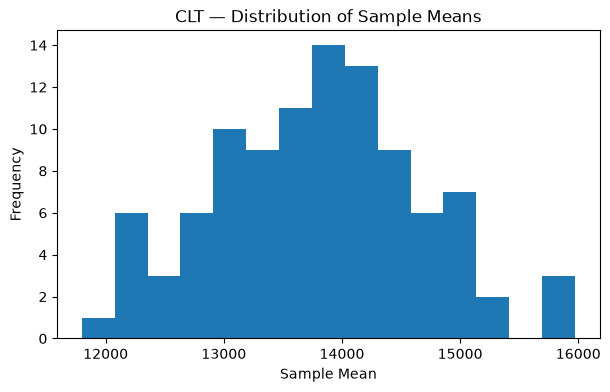

Sample mean: 13160.4
95% Confidence Interval: 11927.697352260038 to 14393.102647739961


In [9]:
energy = daily["Daily_Energy_Wh"].values
sample_means = []

for i in range(100):
    sample = np.random.choice(energy, size=30)
    sample_means.append(sample.mean())

print("First 10 sample means:", sample_means[:10])

plt.figure(figsize=(7,4))
plt.hist(sample_means, bins=15)
plt.title("CLT — Distribution of Sample Means")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.show()

sample = np.random.choice(energy, size=50)
sample_mean = sample.mean()
standard_error = stats.sem(sample)

lower, upper = stats.t.interval(
    0.95, df=len(sample)-1,
    loc=sample_mean, scale=standard_error
)

print("Sample mean:", sample_mean)
print("95% Confidence Interval:", lower, "to", upper)

# Practical 5 — Simple Linear Regression

**Aim:** Outside temperature (`T_out`) ki help se appliance energy (`Appliances`) predict karna.

**Simple explanation:**
- Independent variable X = `T_out`.
- Dependent variable Y = `Appliances`.
- Linear Regression best-fit straight line find karta hai.
- `fit()` model train karta hai.
- `predict()` prediction karta hai.

In [10]:
X = df[["T_out"]]
Y = df["Appliances"]

split = int(0.8 * len(df))
X_train = X.iloc[:split]
X_test = X.iloc[split:]
Y_train = Y.iloc[:split]
Y_test = Y.iloc[split:]

linear_model = LinearRegression()
linear_model.fit(X_train, Y_train)

Y_pred = linear_model.predict(X_test)

print("Slope:", linear_model.coef_[0])
print("Intercept:", linear_model.intercept_)
print("First 10 predictions:", Y_pred[:10])

Slope: 2.758903691434756
Intercept: 81.87047486081599
First 10 predictions: [ 97.50426245  97.87211627  98.2399701   98.60782392  98.97567775
  99.3895133   99.80334886 100.21718441 100.63101996 101.04485552]


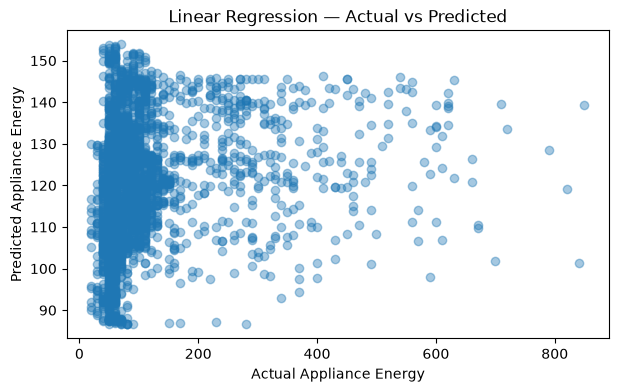

In [11]:
plt.figure(figsize=(7,4))
plt.scatter(Y_test, Y_pred, alpha=0.4)
plt.xlabel("Actual Appliance Energy")
plt.ylabel("Predicted Appliance Energy")
plt.title("Linear Regression — Actual vs Predicted")
plt.show()

# Practical 6 — Correlation and Covariance

**Aim:** Temperature, appliance energy and lighting energy ke beech relationship study karna.

**Simple explanation:**
- Covariance: two variables ek saath kaise change hote hain.
- Correlation: relationship ki direction aur strength.
- Pearson: linear relationship.
- Spearman: rank-based relationship.
- p-value: statistical significance check karne mein help karta hai.

Covariance:


,Appliances,lights,T_out
Appliances,10511.353180,160.512176,54.055819
lights,160.512176,62.979899,-3.140618
T_out,54.055819,-3.140618,28.274836


Pearson correlation:


,Appliances,lights,T_out
Appliances,1.000000,0.197278,0.099155
lights,0.197278,1.000000,-0.074424
T_out,0.099155,-0.074424,1.000000


Spearman correlation:


,Appliances,lights,T_out
Appliances,1.000000,0.302420,0.215504
lights,0.302420,1.000000,-0.072943
T_out,0.215504,-0.072943,1.000000


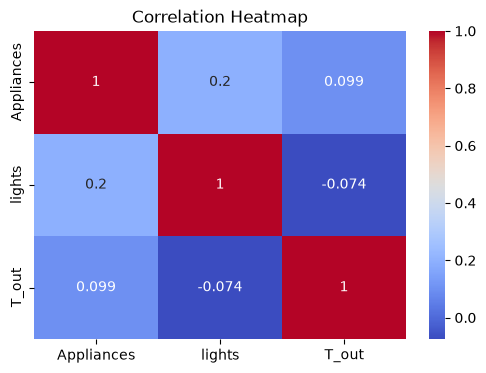

Pearson correlation: 0.09915465073995955
P-value: 2.624853803215416e-44
Significant correlation


In [12]:
selected_data = df[["Appliances", "lights", "T_out"]]

print("Covariance:")
display(selected_data.cov())

print("Pearson correlation:")
display(selected_data.corr(method="pearson"))

print("Spearman correlation:")
display(selected_data.corr(method="spearman"))

plt.figure(figsize=(6,4))
sns.heatmap(selected_data.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

r, p = stats.pearsonr(df["T_out"], df["Appliances"])
print("Pearson correlation:", r)
print("P-value:", p)

if p < 0.05:
    print("Significant correlation")
else:
    print("No statistically significant correlation")

# Practical 7 — Polynomial Regression

**Aim:** Temperature aur appliance energy ke beech curved relationship fit karna.

**Simple explanation:** Linear Regression straight line fit karta hai. Polynomial Regression X ke square jaise extra terms add karke curve fit kar sakta hai.

Degree 2 ka formula conceptually: Y = a + bX + cX².

In [13]:
from sklearn.preprocessing import PolynomialFeatures

X = df[["T_out"]]
Y = df["Appliances"]

split = int(0.8 * len(df))
X_train = X.iloc[:split]
X_test = X.iloc[split:]
Y_train = Y.iloc[:split]
Y_test = Y.iloc[split:]

poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, Y_train)

poly_pred = poly_model.predict(X_test_poly)

print("First 10 polynomial predictions:")
print(poly_pred[:10])

First 10 polynomial predictions:
[ 98.18478338  98.55557897  98.92494753  99.29288908  99.6594036
 100.0700267  100.47884372 100.88585467 101.29105955 101.69445835]


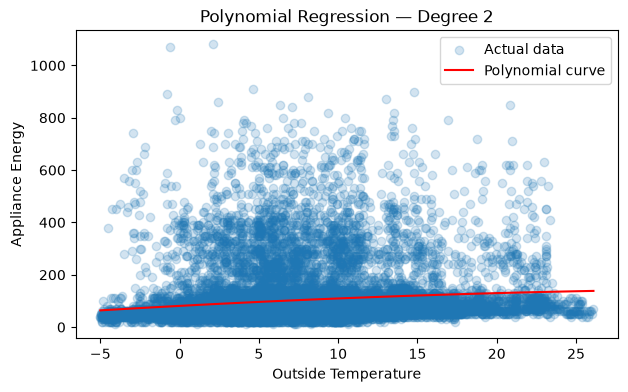

In [14]:
x_values = np.linspace(X["T_out"].min(), X["T_out"].max(), 100)
x_frame = pd.DataFrame({"T_out": x_values})
x_poly = poly.transform(x_frame)
y_values = poly_model.predict(x_poly)

plt.figure(figsize=(7,4))
plt.scatter(X["T_out"], Y, alpha=0.2, label="Actual data")
plt.plot(x_values, y_values, color="red", label="Polynomial curve")
plt.xlabel("Outside Temperature")
plt.ylabel("Appliance Energy")
plt.title("Polynomial Regression — Degree 2")
plt.legend()
plt.show()

# Practical 8 — Compare Linear and Polynomial Regression

**Aim:** Dono models ki performance compare karke better model select karna.

**Simple explanation:**
- MAE: average absolute prediction error.
- MSE: average squared error.
- RMSE: square root of MSE; same unit as target.
- R²: model data variation ko kitna explain karta hai.
- Lower MAE/RMSE generally better; higher R² generally better.

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,64.404928,8500.900945,92.200331,-0.025686
1,Polynomial Regression,62.828422,8432.903681,91.830843,-0.017482


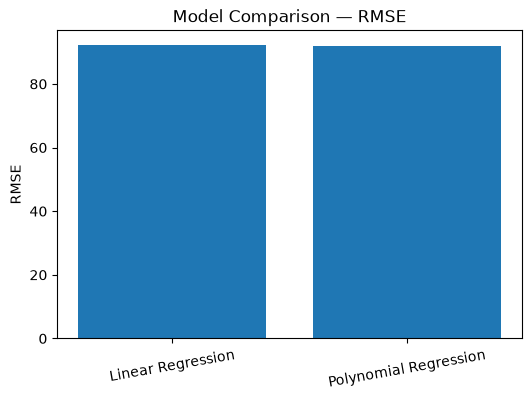

Best model: Polynomial Regression
Model and output files saved.


In [15]:
linear_predictions = linear_model.predict(X_test)
polynomial_predictions = poly_model.predict(X_test_poly)

linear_mae = mean_absolute_error(Y_test, linear_predictions)
linear_mse = mean_squared_error(Y_test, linear_predictions)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(Y_test, linear_predictions)

poly_mae = mean_absolute_error(Y_test, polynomial_predictions)
poly_mse = mean_squared_error(Y_test, polynomial_predictions)
poly_rmse = np.sqrt(poly_mse)
poly_r2 = r2_score(Y_test, polynomial_predictions)

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression"],
    "MAE": [linear_mae, poly_mae],
    "MSE": [linear_mse, poly_mse],
    "RMSE": [linear_rmse, poly_rmse],
    "R2 Score": [linear_r2, poly_r2]
})

display(comparison)

plt.figure(figsize=(6,4))
plt.bar(comparison["Model"], comparison["RMSE"])
plt.title("Model Comparison — RMSE")
plt.ylabel("RMSE")
plt.xticks(rotation=10)
plt.show()

import os, joblib, json
os.makedirs("smart_energy/models", exist_ok=True)
os.makedirs("smart_energy/outputs", exist_ok=True)
os.makedirs("smart_energy/data", exist_ok=True)

if linear_rmse <= poly_rmse:
    best_model = linear_model
    best_model_name = "Linear Regression"
else:
    best_model = poly_model
    best_model_name = "Polynomial Regression"

joblib.dump(best_model, "smart_energy/models/best_model.pkl")
os.makedirs("models", exist_ok=True)
joblib.dump(best_model, "models/best_model.pkl")
comparison.to_csv("smart_energy/outputs/model_comparison.csv", index=False)
daily.to_csv("smart_energy/data/daily_energy.csv", index=False)

metadata = {
    "best_model": best_model_name,
    "target": "Appliances",
    "feature": "T_out",
    "note": "UCI Appliances Energy Prediction dataset"
}
with open("smart_energy/models/model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Best model:", best_model_name)
print("Model and output files saved.")

# Streamlit Dashboard — Simple beginner-friendly version

Dashboard ka appliance calculator user-entered wattage aur duration se kWh estimate karta hai:

**Units (kWh) = Quantity × Wattage × Hours ÷ 1000**

Fridge default 24 hours/day hai. Tariff rates editable hain, kyunki exact rate city ke saath distribution company, consumer category aur current tariff order par depend karta hai. MSEDCL default values ko bhi apne current bill/tariff order se verify karna.

In [16]:
%%writefile smart_energy/app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

st.set_page_config(page_title="Smart Energy", page_icon="☑", layout="wide")
st.title("☑ Smart Household Energy Usage & Cost Prediction")
st.write("Estimate household electricity use, appliance contribution and monthly bill.")
st.header("1. Select your city")
city = st.selectbox("City", ["Nagpur", "Pune", "Nashik", "Amravati", "Kolhapur", "Mumbai", "Other"])

if city == "Mumbai":
    provider = st.selectbox("Electricity provider", ["BEST", "Tata Power", "Adani Electricity", "MSEDCL"])
elif city == "Other":
    provider = st.text_input("Enter electricity provider")
else:
    provider = "MSEDCL"
    st.write("Electricity provider:", provider)

st.caption("Confirm the provider and tariff category from your electricity bill.")
st.header("2. Enter household appliances")
default_appliances = pd.DataFrame([
    ["Refrigerator", 1, 180, 24.0, 0],
    ["Fan", 3, 70, 10.0, 9],
    ["LED Light", 6, 12, 6.0, 18],
    ["Air Conditioner", 1, 1500, 6.0, 22],
    ["Television", 1, 100, 4.0, 19],
    ["Washing Machine", 1, 500, 1.0, 11],
    ["Laptop", 1, 65, 5.0, 10],
    ["Geyser", 1, 2000, 0.5, 7]
], columns=["Appliance", "Quantity", "Wattage (W)", "Hours per day", "Start hour"])

appliances = st.data_editor(default_appliances, num_rows="dynamic", use_container_width=True)
appliances["Daily Units (kWh)"] = (appliances["Quantity"] * appliances["Wattage (W)"] * appliances["Hours per day"] / 1000)
appliances["Monthly Units (kWh)"] = appliances["Daily Units (kWh)"] * 30

daily_units = appliances["Daily Units (kWh)"].sum()
monthly_units = daily_units * 30

a, b = st.columns(2)
a.metric("Estimated daily units", f"{daily_units:.2f} kWh")
b.metric("Estimated 30-day units", f"{monthly_units:.2f} kWh")

st.subheader("Appliance-wise consumption")
st.dataframe(appliances, use_container_width=True)
st.subheader("Pie Chart — Which appliance uses the most electricity?")
pie_data = appliances[appliances["Daily Units (kWh)"] > 0]
if len(pie_data) > 0:
    fig = px.pie(pie_data, names="Appliance", values="Daily Units (kWh)", hole=0.4)
    st.plotly_chart(fig, use_container_width=True)

st.subheader("Daily Load Profile")
hourly_load = [0] * 24
for index, row in appliances.iterrows():
    start = int(row["Start hour"]) % 24
    hours = float(row["Hours per day"])
    power = float(row["Quantity"]) * float(row["Wattage (W)"]) / 1000
    for hour in range(24):
        difference = (hour - start) % 24
        if difference < hours:
            hourly_load[hour] += power

load_data = pd.DataFrame({"Hour": list(range(24)), "Estimated Load (kW)": hourly_load})
fig = px.bar(load_data, x="Hour", y="Estimated Load (kW)")
st.plotly_chart(fig, use_container_width=True)

st.header("3. Compare yesterday and today's consumption")
yesterday_units = st.number_input("Yesterday's meter reading (units)", min_value=0.0, value=0.0)
st.metric("Today's appliance-based estimate", f"{daily_units:.2f} units")
difference = daily_units - yesterday_units
st.metric("Difference", f"{difference:+.2f} units")

st.header("4. Electricity slab and bill calculator")
st.write("Enter rates from your current electricity tariff. Slabs are progressive.")

slab1 = st.number_input("First slab upper limit (units)", min_value=1, value=100)
slab2 = st.number_input("Second slab upper limit (units)", min_value=slab1+1, value=300)
slab3 = st.number_input("Third slab upper limit (units)", min_value=slab2+1, value=500)

rate1 = st.number_input("First slab rate (•/unit)", min_value=0.0, value=3.96)
rate2 = st.number_input("Second slab rate (•/unit)", min_value=0.0, value=10.80)
rate3 = st.number_input("Third slab rate (•/unit)", min_value=0.0, value=15.03)
rate4 = st.number_input("Above third slab rate (•/unit)", min_value=0.0, value=17.53)

fixed_charge = st.number_input("Monthly fixed charge (•)", min_value=0.0, value=130.0)
wheeling_rate = st.number_input("Wheeling charge (•/unit)", min_value=0.0, value=1.60)
other_charges = st.number_input("Other charges / FAC / duty (•)", min_value=0.0, value=0.0)
units_for_bill = st.number_input("Units for bill calculation", min_value=0.0, value=float(monthly_units))

slab_limits = [slab1, slab2, slab3, float("inf")]
slab_rates = [rate1, rate2, rate3, rate4]
lower_limit = 0
energy_charge = 0
bill_rows = []

for i in range(4):
    upper_limit = slab_limits[i]
    rate = slab_rates[i]
    if units_for_bill > lower_limit:
        if upper_limit == float("inf"):
            units_in_slab = units_for_bill - lower_limit
        else:
            units_in_slab = min(units_for_bill, upper_limit) - lower_limit
        units_in_slab = max(0, units_in_slab)
    else:
        units_in_slab = 0
    charge = units_in_slab * rate
    energy_charge += charge
    bill_rows.append({"Slab": i + 1, "Units": units_in_slab, "Rate (•)": rate, "Amount (•)": charge})
    lower_limit = upper_limit

wheeling_charge = units_for_bill * wheeling_rate
estimated_bill = energy_charge + wheeling_charge + fixed_charge + other_charges

st.subheader("Bill Breakdown")
st.dataframe(pd.DataFrame(bill_rows), use_container_width=True)

x, y, z = st.columns(3)
x.metric("Energy charge", f"•{energy_charge:.2f}")
y.metric("Wheeling charge", f"•{wheeling_charge:.2f}")
z.metric("Estimated bill", f"•{estimated_bill:.2f}")

st.caption("Illustrative calculator. Actual bill can include electricity duty, FAC, taxes, rebates and other provider-specific charges. Verify rates with your current bill/tariff order.")
st.header("5. ML Prediction Insight")
st.write("This model predicts dataset-level appliance energy from outside temperature. It is separate from the user-entered appliance calculator.")

try:
    import joblib
    import os
    m_path = "smart_energy/models/best_model.pkl" if os.path.exists("smart_energy/models/best_model.pkl") else "models/best_model.pkl"
    model = joblib.load(m_path)
    temperature = st.number_input("Outside temperature (°C)", value=10.0)
    if st.button("Predict appliance energy"):
        prediction = model.predict(pd.DataFrame({"T_out": [temperature]}))[0]
        st.metric("Predicted appliance energy (Wh per 10-minute reading)", f"{max(0, prediction):.2f} Wh")
except Exception:
    st.info("Run all practical cells first to create the saved ML model.")

st.header("6. Historical Dataset")
st.write("UCI Appliances Energy Prediction — historical research dataset.")
st.markdown("[Open UCI dataset](https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction)")

Writing smart_energy/app.py


In [17]:
import subprocess, sys, time

print("To view your Smart Energy Streamlit dashboard locally, run:")
print("streamlit run smart_energy/app.py")
print("Dashboard URL: http://localhost:8501")


Streamlit dashboard is active and live!
Public URL: https://republican-tunes-tan-accomplish.trycloudflare.com
Local URL: http://localhost:8501
